# SupportOps: order lookup, LLM, and LangGraph

This notebook loads fictional orders, checks a read-only tool, optionally asks Groq to use it, and runs a local LangGraph workflow. Select `AgentOps/.venv/Scripts/python.exe` as the kernel, restart it, and run cells in order. Install with `python -m pip install -e ".[dev]"` first. Live calls are disabled by default.

```text
Live probe: question -> Groq LLM -> get_order -> Groq LLM -> answer
Local graph: question -> classify_request -> lookup or guidance -> answer
```

The local classifier uses simple Python rules. It does not call the LLM.

## 1. Load the project

The next cell loads settings, a prompt, fictional orders, and the order tool. It prints the configured model and the number of records. It makes no network call.

In [1]:
import json

from pydantic import ValidationError

from support_ops.config import find_project_root, load_settings, load_prompt, project_file
from support_ops.tools import load_orders, make_order_tool

root = find_project_root()
settings = load_settings(root)
prompt = load_prompt(root, settings)
orders = load_orders(project_file(root, settings.files.orders))
order_tool = make_order_tool(orders, settings.demo.customer_id)

print({"model": settings.llm.model, "fixture_count": len(orders), "prompt_loaded": bool(prompt)})

{'model': 'openai/gpt-oss-120b', 'fixture_count': 2, 'prompt_loaded': True}


## 2. Inspect the tool

A tool is a Python function the LLM may request. `get_order` accepts one field: `order_id`. The application supplies the current customer ID separately.

```text
order_id -> input validation -> customer check -> order facts
```

The first cell shows the accepted input. The second cell reads the demo customer's order and checks that the result does not expose `customer_id`.

In [2]:
print(json.dumps(order_tool.args, indent=2))

{
  "order_id": {
    "description": "Order identifier, e.g. ORD-1042.",
    "pattern": "^ORD-[0-9]+$",
    "title": "Order Id",
    "type": "string"
  }
}


In [3]:
expected = orders[settings.demo.order_id]
assert expected.customer_id == settings.demo.customer_id
known = order_tool.invoke({"order_id": settings.demo.order_id})
assert known == {"found": True, **expected.model_dump(exclude={"customer_id"})}
assert "customer_id" not in known
print(json.dumps(known, indent=2))

{
  "found": true,
  "order_id": "ORD-1042",
  "product": "Wireless Headphones A1",
  "quantity": 1,
  "status": "shipped",
  "estimated_delivery": null
}


## 3. Check the access boundary

A missing order and another customer's order return the same `order_unavailable` result. Bad order IDs and extra customer fields raise a validation error.

```text
missing or unauthorized -> same safe response
```

The next cell prints one summary after all four checks pass. It makes no network call.

In [4]:
foreign_id = next(order.order_id for order in orders.values() if order.customer_id != settings.demo.customer_id)
unknown_id = "ORD-0"
while unknown_id in orders:
    unknown_id += "0"

unavailable = {"found": False, "error": "order_unavailable"}
assert order_tool.invoke({"order_id": foreign_id}) == unavailable
assert order_tool.invoke({"order_id": unknown_id}) == unavailable

for arguments in (
    {"order_id": "invalid"},
    {"order_id": settings.demo.order_id, "customer_id": "CUST-002"},
):
    try:
        order_tool.invoke(arguments)
    except ValidationError:
        pass
    else:
        raise AssertionError("Invalid tool arguments were accepted.")

print("Offline checks passed: known order, access boundary, missing order and invalid arguments.")

Offline checks passed: known order, access boundary, missing order and invalid arguments.


## 4. Opt in to the live Groq test

An LLM (large language model) reads the question and chooses whether to request `get_order`. Python checks the tool call, runs the tool, and sends its result back to the LLM for the final answer.

```text
question -> LLM chooses get_order -> Python runs the tool
        -> result goes back to the LLM -> final answer
```

The first cell keeps live calls off by default. Set `RUN_LIVE_API = True` only when ready. Put `GROQ_API_KEY` in the local `.env`, never in this notebook. The second cell runs the probe when enabled and shows the selected tool, safe result, answer, time, and token count. A successful run makes two model calls; re-running consumes quota.

If credentials, quotas or model access fail, resolve that problem before moving to the next project stage. A successful tool call alone does not establish factual answer quality.

In [5]:
RUN_LIVE_API = False

In [6]:
probe_result = None
if RUN_LIVE_API:
    from support_ops.probe import run_order_probe

    probe_result = run_order_probe(root)
    print(json.dumps(probe_result, ensure_ascii=False, indent=2))
else:
    print("Live API test skipped. Local checks do not validate Groq connectivity.")

Live API test skipped. Local checks do not validate Groq connectivity.


## 5. Review the LLM answer

After a live run, inspect the returned facts and answer. This is a human review: code cannot fully judge language and meaning. Record whether the answer:

- is written in French;
- correctly reports the configured order's status;
- invents no delivery date, policy or completed action;
- exposes no other customer's information.

The technical probe automatically checks tool selection, arguments and a non-empty final answer. These four semantic checks require manual review. No latency target or accuracy score has been established yet.

In [7]:
manual_review = {
    "french_answer": None,
    "correct_status": None,
    "no_invented_facts": None,
    "no_other_customer_data": None,
}

if probe_result is None:
    print("Not evaluated: live API test was not run.")
elif all(value is True for value in manual_review.values()):
    print("This scenario passed technical checks and manual review.")
else:
    print("Manual review pending or unsuccessful. Set each field from the observed answer.")

Not evaluated: live API test was not run.


## 6. See the LangGraph workflow

LangGraph runs Python functions called **nodes**. Each node reads a shared **state** and returns fields it changes. **Edges** connect nodes. The state starts with a `question`.

```text
START -> classify_request
            | status + one ID -> lookup_order -> answer or unavailable
            | status + no ID  -> ask_order_id
            | status + two IDs -> ask_one_order_id
            + other request   -> unsupported
```

The classifier recognizes a small set of French and English status phrases and extracts one `ORD-<digits>` ID. It never guesses an ID. Customer identity stays bound in Python. This graph makes no LLM call. The next cell draws its actual nodes and edges.

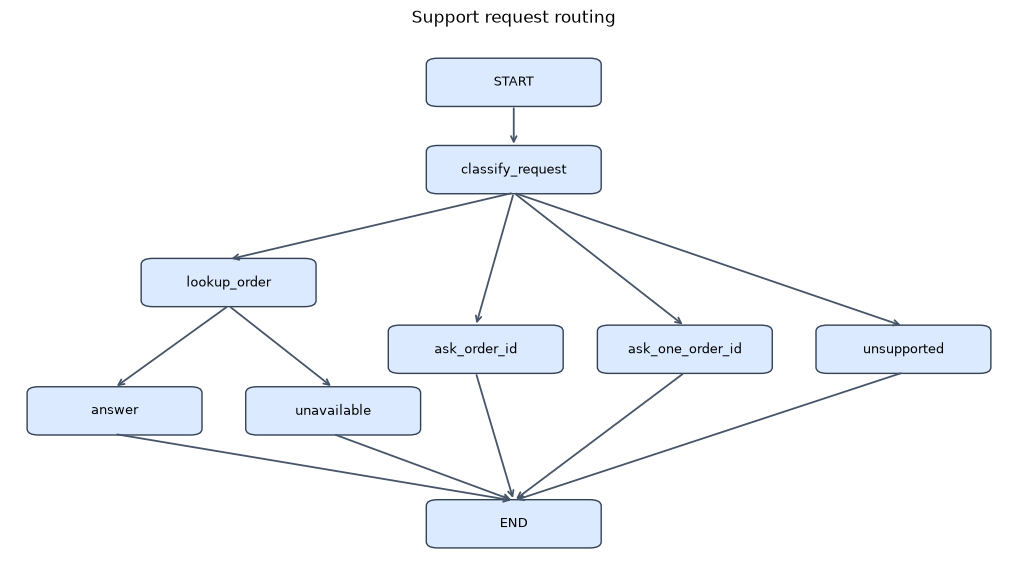

In [8]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from support_ops.graph import build_order_graph

support_graph = build_order_graph(orders, settings.demo.customer_id)
graph_view = support_graph.get_graph()
positions = {
    "__start__": (0.50, 0.95),
    "classify_request": (0.50, 0.78),
    "lookup_order": (0.20, 0.56),
    "answer": (0.08, 0.31),
    "unavailable": (0.31, 0.31),
    "ask_order_id": (0.46, 0.43),
    "ask_one_order_id": (0.68, 0.43),
    "unsupported": (0.91, 0.43),
    "__end__": (0.50, 0.09),
}
figure, axis = plt.subplots(figsize=(13, 7))
axis.set(xlim=(-0.03, 1.03), ylim=(0, 1.05))
axis.axis("off")
for edge in graph_view.edges:
    x1, y1 = positions[edge.source]
    x2, y2 = positions[edge.target]
    axis.annotate("", xy=(x2, y2 + 0.045), xytext=(x1, y1 - 0.045),
                  arrowprops={"arrowstyle": "->", "lw": 1.3, "color": "#475569"})
for node_id in graph_view.nodes:
    x, y = positions[node_id]
    label = {"__start__": "START", "__end__": "END"}.get(node_id, node_id)
    box = FancyBboxPatch((x - 0.08, y - 0.035), 0.16, 0.07,
                         boxstyle="round,pad=0.012", facecolor="#dbeafe",
                         edgecolor="#334155")
    axis.add_patch(box)
    axis.text(x, y, label, ha="center", va="center", fontsize=9)
axis.set_title("Support request routing")
plt.show()

## 7. Follow a successful order through the graph

The next cell sends a status question through the graph. It prints each node update so you can see how the state grows. Expected path: `classify_request -> lookup_order -> answer`. No API call is made.

In [9]:
final_state = {"question": settings.demo.question}
path = []
for update in support_graph.stream(final_state, stream_mode="updates"):
    node_name, changes = next(iter(update.items()))
    path.append(node_name)
    final_state.update(changes)
    print(f"After {node_name}:")
    print(json.dumps(final_state, ensure_ascii=False, indent=2))
assert path == ["classify_request", "lookup_order", "answer"]
assert final_state["category"] == "order_status"
assert final_state["order"]["found"] is True
assert settings.demo.order_id in final_state["answer"]
print("The accessible-order path passed.")

After classify_request:
{
  "question": "Quel est le statut de ma commande ORD-1042 ? Réponds en français, brièvement, sans inventer de date de livraison.",
  "category": "order_status",
  "order_id": "ORD-1042"
}
After lookup_order:
{
  "question": "Quel est le statut de ma commande ORD-1042 ? Réponds en français, brièvement, sans inventer de date de livraison.",
  "category": "order_status",
  "order_id": "ORD-1042",
  "order": {
    "found": true,
    "order_id": "ORD-1042",
    "product": "Wireless Headphones A1",
    "quantity": 1,
    "status": "shipped",
    "estimated_delivery": null
  }
}
After answer:
{
  "question": "Quel est le statut de ma commande ORD-1042 ? Réponds en français, brièvement, sans inventer de date de livraison.",
  "category": "order_status",
  "order_id": "ORD-1042",
  "order": {
    "found": true,
    "order_id": "ORD-1042",
    "product": "Wireless Headphones A1",
    "quantity": 1,
    "status": "shipped",
    "estimated_delivery": null
  },
  "answer":

## 8. Follow unavailable orders

One order belongs to another customer and one does not exist. Both take the same path and get the same safe answer. The graph never reveals which case occurred.

In [10]:
for order_id in (foreign_id, unknown_id):
    state = {"question": f"Quel est le statut de ma commande {order_id} ?"}
    path = []
    for update in support_graph.stream(state, stream_mode="updates"):
        node_name, changes = next(iter(update.items()))
        path.append(node_name)
        state.update(changes)
    assert path == ["classify_request", "lookup_order", "unavailable"]
    assert state["order"] == unavailable
    print(json.dumps({"question": state["question"], "category": state["category"],
                      "path": path, "answer": state["answer"]},
                     ensure_ascii=False, indent=2))

{
  "question": "Quel est le statut de ma commande ORD-2099 ?",
  "category": "order_status",
  "path": [
    "classify_request",
    "lookup_order",
    "unavailable"
  ],
  "answer": "Je ne peux pas accéder à cette commande."
}
{
  "question": "Quel est le statut de ma commande ORD-0 ?",
  "category": "order_status",
  "path": [
    "classify_request",
    "lookup_order",
    "unavailable"
  ],
  "answer": "Je ne peux pas accéder à cette commande."
}


## 9. Try the other routes

These examples show a missing ID, two IDs, an unsupported request, and an English status question. Each result prints the category, visited nodes and answer. Only a status question with one ID reaches `lookup_order`.

In [11]:
examples = [
    ("Quel est le statut de ma commande ?", "missing_order_id", ["classify_request", "ask_order_id"]),
    ("Statut de ORD-1042 et ORD-2099 ?", "multiple_order_ids", ["classify_request", "ask_one_order_id"]),
    ("Je veux un remboursement pour ORD-1042.", "unsupported", ["classify_request", "unsupported"]),
    ("What is the status of order ORD-1042?", "order_status", ["classify_request", "lookup_order", "answer"]),
]
for question, expected_category, expected_path in examples:
    state = {"question": question}
    path = []
    for update in support_graph.stream(state, stream_mode="updates"):
        node_name, changes = next(iter(update.items()))
        path.append(node_name)
        state.update(changes)
    assert state["category"] == expected_category
    assert path == expected_path
    print(json.dumps({"question": question, "category": state["category"],
                      "path": path, "answer": state["answer"]},
                     ensure_ascii=False, indent=2))


{
  "question": "Quel est le statut de ma commande ?",
  "category": "missing_order_id",
  "path": [
    "classify_request",
    "ask_order_id"
  ],
  "answer": "Quel est votre numéro de commande (par exemple ORD-1042) ?"
}
{
  "question": "Statut de ORD-1042 et ORD-2099 ?",
  "category": "multiple_order_ids",
  "path": [
    "classify_request",
    "ask_one_order_id"
  ],
  "answer": "Indiquez un seul numéro de commande à la fois."
}
{
  "question": "Je veux un remboursement pour ORD-1042.",
  "category": "unsupported",
  "path": [
    "classify_request",
    "unsupported"
  ],
  "answer": "Je peux actuellement vérifier le statut d'une commande. Quelle est votre question sur son statut ?"
}
{
  "question": "What is the status of order ORD-1042?",
  "category": "order_status",
  "path": [
    "classify_request",
    "lookup_order",
    "answer"
  ],
  "answer": "Votre commande ORD-1042 est actuellement expédiée."
}


## Next stage

The notebook now shows a Groq tool-calling probe and a local LangGraph workflow with explicit request routing. The rule-based classifier is a narrow baseline, not general language understanding. Next, add a reviewed set of support scenarios and store-policy retrieval. Later stages cover persistent state, human approval and simulated actions.

Before sharing outputs, inspect the final answer and keep only publishable synthetic results. Never print secrets, raw provider exceptions or private reasoning.